# College Graduate Salary Prediction Using Machine Learning

## Research Objective
This project explores whether machine learning can predict college graduates' salaries using their field of study, university, GPA, and years of experience.

Two models are compared: Linear Regression and Random Forest Regression.

##1. Dataset

In [36]:
import pandas as pd

data = pd.read_csv("job_placement.csv")
print(data.shape)
data.head(10)

(700, 11)


,id,name,gender,age,degree,stream,college_name,placement_status,salary,gpa,years_of_experience
0,1,John Doe,Male,25,Bachelor's,Computer Science,Harvard University,Placed,60000,3.7,2.0
1,2,Jane Smith,Female,24,Bachelor's,Electrical Engineering,Massachusetts Institute of Technology,Placed,65000,3.6,1.0
2,3,Michael Johnson,Male,26,Bachelor's,Mechanical Engineering,Stanford University,Placed,58000,3.8,3.0
3,4,Emily Davis,Female,23,Bachelor's,Information Technology,Yale University,Not Placed,0,3.5,2.0
4,5,David Brown,Male,24,Bachelor's,Computer Science,Princeton University,Placed,62000,3.9,2.0
5,6,Sarah Wilson,Female,25,Bachelor's,Electronics and Communication,Columbia University,Placed,63000,3.7,1.0
6,7,James Martinez,Male,26,Bachelor's,Information Technology,California Institute of Technology,Placed,59000,3.8,3.0
7,8,Emma Garcia,Female,24,Bachelor's,Computer Science,University of Chicago,Not Placed,0,3.6,2.0
8,9,Alexander Taylor,Male,25,Bachelor's,Electrical Engineering,University of Pennsylvania,Placed,64000,3.7,2.0
9,10,Samantha Anderson,Female,23,Bachelor's,Mechanical Engineering,Northwestern University,Placed,57000,3.5,1.0


## 2. Data Preprocessing

In [37]:
# check column names and data types
print(data.dtypes)

# check missing values
print(data.isnull().sum())

# check duplicate rows
print(data.duplicated().sum())

id                       int64
name                    object
gender                  object
age                      int64
degree                  object
stream                  object
college_name            object
placement_status        object
salary                   int64
gpa                    float64
years_of_experience    float64
dtype: object
id                     0
name                   0
gender                 0
age                    0
degree                 0
stream                 0
college_name           0
placement_status       0
salary                 0
gpa                    0
years_of_experience    1
dtype: int64
0


In [38]:
# keep students who were placed
data = data[(data["placement_status"] == "Placed") & (data["salary"] > 0)].copy()

# remove rows with missing values
data = data.dropna()

# check the cleaned dataset
print(data.shape)
print(data.isnull().sum())

(569, 11)
id                     0
name                   0
gender                 0
age                    0
degree                 0
stream                 0
college_name           0
placement_status       0
salary                 0
gpa                    0
years_of_experience    0
dtype: int64


## 3.Feature Selection

In [39]:
# Select the features and target
X = data[["stream", "college_name", "gpa", "years_of_experience"]]
y = data["salary"]

print(X.shape)
print(y.shape)
X.head()

(569, 4)
(569,)


,stream,college_name,gpa,years_of_experience
0,Computer Science,Harvard University,3.7,2.0
1,Electrical Engineering,Massachusetts Institute of Technology,3.6,1.0
2,Mechanical Engineering,Stanford University,3.8,3.0
4,Computer Science,Princeton University,3.9,2.0
5,Electronics and Communication,Columbia University,3.7,1.0


In [40]:
# check how many universities are in the dataset
print(data["college_name"].nunique())

# show the universities
print(data["college_name"].unique())

37
['Harvard University' 'Massachusetts Institute of Technology'
 'Stanford University' 'Princeton University' 'Columbia University'
 'California Institute of Technology' 'University of Pennsylvania'
 'Northwestern University' 'Duke University'
 'University of California--Berkeley' 'University of Michigan--Ann Arbor'
 'University of California--Los Angeles'
 'University of Wisconsin--Madison'
 'University of Illinois--Urbana-Champaign'
 'University of North Carolina--Chapel Hill' 'University of Washington'
 'University of California--San Diego'
 'University of California--Santa Barbara'
 'University of Southern California' 'University of Florida'
 'University of Maryland--College Park' 'University of California--Davis'
 'University of Pittsburgh' 'University of Colorado--Boulder'
 'University of Rochester' 'Rice University'
 'University of California--Irvine' 'Georgetown University'
 'University of Notre Dame' 'University of Iowa'
 'University of California--Santa Cruz' 'University of 

## 4.Train/Test Split

In [41]:
from sklearn.model_selection import train_test_split

# split the data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape)
print(X_test.shape)

(455, 4)
(114, 4)


## 5. Categorical Encoding

In [42]:
import pandas as pd

# convert text columns into numbers
X_train = pd.get_dummies(X_train, dtype=int)
X_test = pd.get_dummies(X_test, dtype=int)

# make sure both have the same columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape)
print(X_test.shape)

(455, 41)
(114, 41)


## 6. Linear Regression

In [43]:
from sklearn.linear_model import LinearRegression

# train linear regression model
linear = LinearRegression()
linear.fit(X_train, y_train)

# predict salaries
linear_pred = linear.predict(X_test)

print(linear_pred[:10])

[63022.21139622 66581.99746675 64339.08317381 60926.06400967
 66112.38392798 65073.97299456 63039.76889427 65295.85824682
 65976.3057017  65957.33317702]


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# calculate errors for linear regression
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 350.27533337973074
Linear Regression RMSE: 911.9520007737815


## 7. Random Forest Regression

In [45]:
from sklearn.ensemble import RandomForestRegressor

# train random forest model
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)

# predict salaries
forest_pred = forest.predict(X_test)

print(forest_pred[:10])

[63000.         66824.25793651 64000.         61000.
 65853.78778166 65000.         63000.         66150.
 66000.         66000.        ]


In [46]:
# calculate errors for random forest
forest_mae = mean_absolute_error(y_test, forest_pred)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_pred))

print("Random Forest MAE:", forest_mae)
print("Random Forest RMSE:", forest_rmse)

Random Forest MAE: 218.681674175447
Random Forest RMSE: 915.5357695693358


## 8. Model Comparison

In [47]:
# compare both models
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, forest_mae],
    "RMSE": [linear_rmse, forest_rmse]
})

print(results)

               Model         MAE        RMSE
0  Linear Regression  350.275333  911.952001
1      Random Forest  218.681674  915.535770


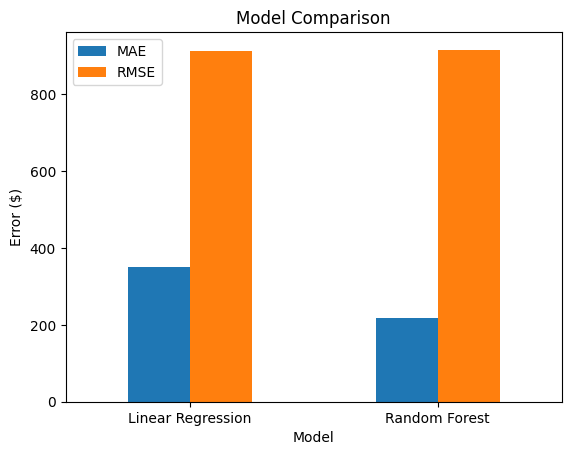

In [48]:
import matplotlib.pyplot as plt

# compare model errors
results.plot(x="Model", y=["MAE", "RMSE"], kind="bar")

plt.title("Model Comparison")
plt.ylabel("Error ($)")
plt.xticks(rotation=0)
plt.show()